# capsule：元画像・10回反復・edge回転拡張の比較学習
2026-10-22に決めた比較設計です。bottleと同じHybrid CNN＋FCを使い、データをcapsuleへ変更します。

| 条件 | 元画像 | 1エポックの延べ枚数 | 100エポックの更新回数 |
|---|---:|---:|---:|
| A：元画像 | 219 | 219 | 700 |
| B：10回反復 | 219 | 2,190 | 6,900 |
| C：edgeで10方向回転 | 219 | 2,190 | 6,900 |

全条件で元画像1000×1000全体→LANCZOSで128×128→白黒→0〜1。Cだけ縮小前にedge補完と回転を行い、回転後の枠を1000×1000に保ちます。0〜324度・36度刻みで、各角度は同じ元画像から直接生成します。
初期重み・乱数・B/Cの元画像対応と入力順を揃えます。A/Bの差は反復・更新量・更新に対するβの進み方も含み、回転だけの効果はB/Cで調べます。
単一シードの結果で一般的な優劣は断定しません。capsuleとbottleの差も形状だけの影響とは言えません。

## 使い方
1. まず初期設定のまま上から実行し、プレビューと少量の動作確認を確認。
2. 正式学習を開始するときは `RUN_FULL_TRAINING=True` にして、上から実行。CPUでは長時間かかります。
3. 完了した実行IDを、別の「capsuleの画像反復とedge回転拡張モデルのAUROC比較」ノートブックで指定。

**初期状態では正式学習しません。** 動作確認のモデルは一時領域だけに保存し、正式結果として残しません。

In [ ]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

from pathlib import Path
from io import BytesIO
from datetime import datetime
from zoneinfo import ZoneInfo
import copy
import hashlib
import importlib.metadata
import json
import math
import platform
import random
import time
import uuid
import tempfile

import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

%matplotlib inline

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'code' / '202607' / '260718拡張データによる学習.ipynb').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('このリポジトリ内を作業ディレクトリにしてください。')

TRAIN_DIR = ROOT / 'data/capsule/train/good'
NORMAL_TEST_DIR = ROOT / 'data/capsule/test/good'
OUTPUT_BASE = ROOT / 'saved_models/capsule_rotation_control_20261022'
RUN_FULL_TRAINING = True
RUN_SMOKE_TEST = True

SEEDS = [42]  # 複数シードで調べる場合は例：[42, 43, 44]。各シードでA/B/Cを実行。
EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
LATENT_DIM = 64
ANNEALING_EPOCHS = 50
ANGLES = tuple(range(0, 360, 36))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_WORKERS = 0  # Notebook/Windowsで確実に実行し、B/Cの順序を保つ。
CONDITIONS = ('A_original', 'B_repeat10', 'C_rotate10')
CONDITION_LABELS = {'A_original': 'A：元画像', 'B_repeat10': 'B：10回反復', 'C_rotate10': 'C：edge回転拡張'}
EXPERIMENT = 'capsule_rotation_control_20261022_edge'
EXPECTED_SOURCE_SIZE = (1000,1000)

assert len(SEEDS) > 0 and len(set(SEEDS)) == len(SEEDS)
assert EPOCHS > 0 and BATCH_SIZE >= 2 and ANNEALING_EPOCHS > 0
assert ANGLES == (0, 36, 72, 108, 144, 180, 216, 252, 288, 324)
torch.set_num_threads(min(4, max(1, torch.get_num_threads())))
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

available_fonts = {f.name for f in font_manager.fontManager.ttflist}
for font in ['Yu Gothic', 'Meiryo', 'MS Gothic', 'Noto Sans CJK JP', 'IPAexGothic']:
    if font in available_fonts:
        plt.rcParams['font.family'] = font
        break
else:
    import japanize_matplotlib
plt.rcParams.update({'font.size': 11, 'axes.unicode_minus': False, 'figure.dpi': 100})
print(f'デバイス：{DEVICE} / 正式学習：{RUN_FULL_TRAINING} / seeds：{SEEDS}')

デバイス：cpu / 正式学習：False / seeds：[42]


## 1. 元画像全体と、3条件のデータを準備する
高解像度の画像は読み取り専用で使い、拡張PNGは作りません。Cの入力テンソルはメモリ内に用意します。

In [2]:
# 全条件で画像全体を使う。中央820の切り出しは行わない。
final_transform=transforms.Compose([
    transforms.Resize((128,128),interpolation=transforms.InterpolationMode.LANCZOS),
    transforms.Grayscale(num_output_channels=1),
])
to_tensor=transforms.ToTensor()
def edge_pad_width(size):
    return math.ceil((math.hypot(*size)-min(size))/2)+4

def rotate_with_edge(image,angle,verify_support=False):
    if angle==0: return image.copy()
    width,height=image.size
    pad=edge_pad_width(image.size)
    pixels=np.asarray(image)
    extended=Image.fromarray(np.pad(pixels,((pad,pad),(pad,pad),(0,0)),mode='edge'))
    box=(pad,pad,pad+width,pad+height)
    options=dict(interpolation=transforms.InterpolationMode.NEAREST,expand=False)
    out=TF.rotate(extended,angle=angle,fill=255,**options).crop(box)
    mask=TF.rotate(Image.new('L',image.size,255),angle=angle,fill=0,**options)
    original_part=TF.rotate(image,angle=angle,fill=255,**options)
    valid=np.asarray(mask)>0
    result=np.asarray(out).copy()
    result[valid]=np.asarray(original_part)[valid]
    if verify_support:
        support=TF.rotate(Image.new('L',extended.size,255),angle=angle,fill=0,**options).crop(box)
        assert np.all(np.asarray(support)==255),'パディングが不足しています。'
        assert np.array_equal(result[valid],np.asarray(original_part)[valid])
    return Image.fromarray(result)

def read_base_images(directory):
    paths=sorted(directory.glob('*.png'),key=lambda p:p.name)
    if not paths: raise FileNotFoundError(directory)
    images,manifest=[],[]
    for path in paths:
        raw=path.read_bytes()
        with Image.open(BytesIO(raw)) as im: image=im.convert('RGB').copy()
        if image.size!=EXPECTED_SOURCE_SIZE: raise ValueError(f'画像サイズが変更されています：{path} {image.size}')
        tensor=to_tensor(final_transform(image))
        images.append(image)
        manifest.append({'path':path.relative_to(ROOT).as_posix(),
                         'source_size':list(image.size),'edge_pad_width':edge_pad_width(image.size),
                         'file_sha256':hashlib.sha256(raw).hexdigest(),
                         'preprocessed_sha256':hashlib.sha256(tensor.numpy().tobytes()).hexdigest()})
    return images,manifest

class RotationControlDataset(Dataset):
    def __init__(self,base_images,condition):
        if condition not in CONDITIONS: raise ValueError(condition)
        self.condition=condition
        self.base_images=base_images
        self.base_tensors=torch.stack([to_tensor(final_transform(im)) for im in base_images])
        self.repeats=1 if condition=='A_original' else len(ANGLES)
        self.rotated_tensors=None
        if condition=='C_rotate10':
            variants=[]
            for parent,image in enumerate(base_images):
                for angle in ANGLES:
                    variants.append(to_tensor(final_transform(rotate_with_edge(image,angle,verify_support=(parent==0)))))
                if len(base_images)>20 and (parent+1)%50==0: print(f'回転入力の準備：{parent+1}/{len(base_images)}枚',flush=True)
            self.rotated_tensors=torch.stack(variants)
    def __len__(self): return len(self.base_images)*self.repeats
    def __getitem__(self,index):
        parent,variant=divmod(index,self.repeats)
        image=self.rotated_tensors[index] if self.rotated_tensors is not None else self.base_tensors[parent]
        return image,parent,variant

def loader_for(dataset,seed,batch_size=BATCH_SIZE):
    if len(dataset)%batch_size==1: raise ValueError('BatchNorm用に最終バッチ1枚を避けてください。')
    generator=torch.Generator().manual_seed(int(seed)+1000)
    return DataLoader(dataset,batch_size=batch_size,shuffle=True,generator=generator,drop_last=False,num_workers=NUM_WORKERS)

train_images,train_manifest=read_base_images(TRAIN_DIR)
normal_test_images,normal_test_manifest=read_base_images(NORMAL_TEST_DIR)
assert len(train_images)==219 and len(normal_test_images)==23
assert not {r['file_sha256'] for r in train_manifest}&{r['file_sha256'] for r in normal_test_manifest}
assert not {r['preprocessed_sha256'] for r in train_manifest}&{r['preprocessed_sha256'] for r in normal_test_manifest}
datasets={name:RotationControlDataset(train_images,name) for name in CONDITIONS}
normal_test_tensor=torch.stack([to_tensor(final_transform(im)) for im in normal_test_images])
assert len(datasets['A_original'])==219 and len(datasets['B_repeat10'])==len(datasets['C_rotate10'])==2190
for parent in range(len(train_images)):
    for variant in range(10):
        assert torch.equal(datasets['A_original'][parent][0],datasets['B_repeat10'][parent*10+variant][0])
    assert torch.equal(datasets['A_original'][parent][0],datasets['C_rotate10'][parent*10][0])
condition_table=pd.DataFrame([{'条件':CONDITION_LABELS[name],'元画像数':len(train_images),'1エポックの延べ枚数':len(ds),
 '更新回数/エポック':math.ceil(len(ds)/BATCH_SIZE),'エポック数':EPOCHS,'総更新回数':EPOCHS*math.ceil(len(ds)/BATCH_SIZE)} for name,ds in datasets.items()])
display(condition_table)
print('共通正常テスト23枚は学習・モデル選択に使いません。')

回転入力の準備：50/219枚


回転入力の準備：100/219枚


回転入力の準備：150/219枚


回転入力の準備：200/219枚


,条件,元画像数,1エポックの延べ枚数,更新回数/エポック,エポック数,総更新回数
0,A：元画像,219,219,7,100,700
1,B：10回反復,219,2190,69,100,6900
2,C：edge回転拡張,219,2190,69,100,6900


共通正常テスト23枚は学習・モデル選択に使いません。


## 2. 入力画像を確認する

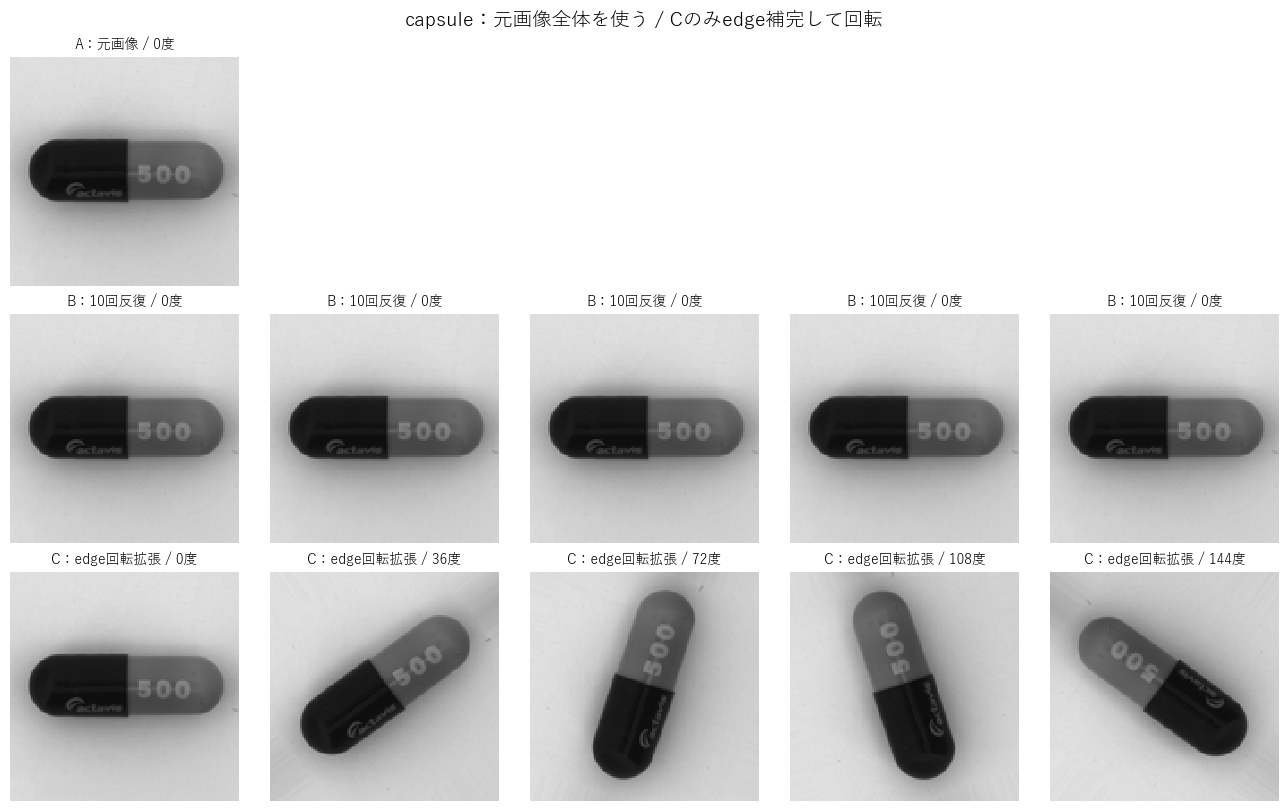

In [2]:
fig,axes=plt.subplots(3,5,figsize=(13,8),constrained_layout=True)
for row,name in enumerate(CONDITIONS):
    for col in range(5):
        if name=='A_original' and col>0:
            axes[row,col].set_visible(False)
            continue
        index=0 if name=='A_original' else col
        image,parent,variant=datasets[name][index]
        axes[row,col].imshow(image[0],cmap='gray',vmin=0,vmax=1,interpolation='nearest')
        angle=ANGLES[variant] if name=='C_rotate10' else 0
        axes[row,col].set_title(f'{CONDITION_LABELS[name]} / {angle}度',fontsize=10)
        axes[row,col].axis('off')
fig.suptitle('capsule：元画像全体を使う / Cのみedge補完して回転',fontsize=14)
plt.show();plt.close(fig)

## 3. モデルと損失
既存bottle実験と同じモデルです。学習は潜在変数のサンプリング、共通正常画像の評価は平均推論を使います。

In [4]:
class VAE_Hybrid_CNN_FC(nn.Module):
    def __init__(self, latent_dim=64):
        super(VAE_Hybrid_CNN_FC, self).__init__()

        # -------------------------------------------------------------
        # 【エンコーダ前半】 CNN_Deep5（空間圧縮: 128x128 -> 4x4）
        # -------------------------------------------------------------
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),

            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(256), nn.ReLU()
        )

        # -------------------------------------------------------------
        # 【エンコーダ後半】 FC_Only（段階的圧縮: 4096次元 -> 128次元）
        # -------------------------------------------------------------
        self.encoder_fc = nn.Sequential(
            nn.Linear(256 * 4 * 4, 1024), nn.ReLU(),
            nn.Linear(1024, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU()
        )

        # 潜在空間へのマッピング（128次元 -> 64次元）
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        # -------------------------------------------------------------
        # 【デコーダ前半】 FC_Only（段階的復元: 64次元 -> 4096次元）
        # -------------------------------------------------------------
        self.decoder_fc = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 1024), nn.ReLU(),
            # ※CNNへ繋ぐため、最後はSigmoidではなくReLUを使用します
            nn.Linear(1024, 256 * 4 * 4), nn.ReLU()
        )

        # -------------------------------------------------------------
        # 【デコーダ後半】 CNN_Deep5（空間復元: 4x4 -> 128x128）
        # -------------------------------------------------------------
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),

            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),

            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),

            nn.ConvTranspose2d(16, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x, sample=True):
        # 1. CNNによる特徴抽出
        h = self.encoder_conv(x)
        h = torch.flatten(h, start_dim=1)

        # 2. FCによる段階的圧縮
        h = self.encoder_fc(h)

        # 3. 潜在変数の計算と安全装置（クランプ）
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        logvar = torch.clamp(logvar, min=-10.0, max=10.0)

        std = torch.exp(0.5 * logvar)
        z = mu + torch.randn_like(std) * std if sample else mu

        # 4. FCによる段階的復元
        h_recon = self.decoder_fc(z)
        h_recon = h_recon.view(-1, 256, 4, 4) # 4階テンソルに戻す

        # 5. CNNによる画像復元
        recon = self.decoder_conv(h_recon)

        return recon, mu, logvar

def vae_loss(recon_x, x, mu, logvar, beta=1.0):  
    MSE = nn.functional.mse_loss(recon_x, x, reduction='sum')
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return MSE, KLD, MSE + beta * KLD

def seed_everything(seed):
    random.seed(int(seed))
    np.random.seed(int(seed))
    torch.manual_seed(int(seed))
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(int(seed))

def copy_cpu_state(model):
    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

def state_digest(state):
    digest = hashlib.sha256()
    for name in sorted(state):
        tensor = state[name].detach().cpu().contiguous()
        digest.update(name.encode('utf-8') + str(tensor.dtype).encode('ascii'))
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()

def make_initial_state(seed):
    seed_everything(seed)
    initial_model = VAE_Hybrid_CNN_FC(latent_dim=LATENT_DIM)
    return copy_cpu_state(initial_model)

def new_model(initial_state, seed, device=DEVICE):
    model = VAE_Hybrid_CNN_FC(latent_dim=LATENT_DIM).to(device)
    model.load_state_dict(initial_state, strict=True)
    # モデル構築で消費された乱数を戻し、各条件のサンプリング列を揃える。
    seed_everything(seed)
    return model

## 4. 学習と共通正常画像の復元評価
学習画像上のSSEと、共通の未学習正常画像23枚のSSEを区別します。最終エポックだけを評価し、テストでモデルを選びません。

In [5]:
def train_epoch(model, loader, optimizer, beta, device, order_digest, max_batches=None):
    model.train()
    sums = np.zeros(3, dtype=np.float64)
    seen, updates = 0, 0
    for images, parents, variants in loader:
        if max_batches is not None and updates >= max_batches:
            break
        pair_order = torch.stack([parents, variants], dim=1).numpy().astype('<i8', copy=False)
        order_digest.update(pair_order.tobytes())
        images = images.to(device)
        optimizer.zero_grad(set_to_none=True)
        reconstruction, mu, logvar = model(images, sample=True)
        mse, kld, loss = vae_loss(reconstruction, images, mu, logvar, beta=beta)
        if not all(torch.isfinite(value).item() for value in [mse, kld, loss]):
            raise FloatingPointError('損失にNaN/infが発生しました。')
        loss.backward()
        if any(p.grad is not None and not torch.isfinite(p.grad).all().item() for p in model.parameters()):
            raise FloatingPointError('勾配にNaN/infが発生しました。')
        optimizer.step()
        sums += [mse.item(), kld.item(), loss.item()]
        seen += len(images)
        updates += 1
    if not seen:
        raise ValueError('学習バッチがありません。')
    return {'train_sse_per_image': float(sums[0] / seen),
            'train_kl_per_image': float(sums[1] / seen),
            'train_total_per_image': float(sums[2] / seen),
            'seen_images': seen, 'updates': updates}

def evaluate_normal(model, images, names, device=DEVICE):
    model.eval()
    rows = []
    with torch.inference_mode():
        for start in range(0, len(images), BATCH_SIZE):
            inputs = images[start:start + BATCH_SIZE].to(device)
            reconstruction, _, _ = model(inputs, sample=False)
            per_image = (inputs - reconstruction).square().flatten(1).sum(1).cpu().numpy()
            if not np.isfinite(per_image).all():
                raise FloatingPointError('評価誤差にNaN/infが発生しました。')
            for name, error in zip(names[start:start + BATCH_SIZE], per_image):
                rows.append({'path': name, 'sse_per_image': float(error),
                             'mse_per_pixel': float(error / (128 * 128))})
    return pd.DataFrame(rows)

def write_json(path, value):
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')

def train_condition(condition, seed, initial_state, directory):
    directory.mkdir(parents=True, exist_ok=False)
    dataset = datasets[condition]
    loader = loader_for(dataset, seed)
    model = new_model(initial_state, seed)
    initial_hash = state_digest(copy_cpu_state(model))
    if initial_hash != state_digest(initial_state):
        raise AssertionError('初期重みが一致しません。')
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    order_digest = hashlib.sha256()
    history = []
    total_updates = 0
    started = time.perf_counter()
    for epoch in range(EPOCHS):
        beta = min(1.0, epoch / ANNEALING_EPOCHS)
        values = train_epoch(model, loader, optimizer, beta, DEVICE, order_digest)
        assert values['seen_images'] == len(dataset) and values['updates'] == len(loader)
        total_updates += values['updates']
        history.append({'epoch': epoch + 1, 'beta': beta,
                        'cumulative_updates': total_updates, **values})
        pd.DataFrame(history).to_csv(directory / 'history.csv', index=False)
        if epoch == 0 or (epoch + 1) % 10 == 0 or epoch + 1 == EPOCHS:
            print(f'{condition} / seed={seed} / epoch={epoch + 1:3d}/{EPOCHS} '
                  f'/ beta={beta:.2f} / train SSE={values["train_sse_per_image"]:.4f} '
                  f'/ updates={total_updates}', flush=True)

    assert total_updates == EPOCHS * math.ceil(len(dataset) / BATCH_SIZE)
    # エポック選択はせず、固定した最終エポックだけを共通テストで確認する。
    normal_results = evaluate_normal(model, normal_test_tensor,
                                     [r['path'] for r in normal_test_manifest])
    normal_results.to_csv(directory / 'normal_test_errors.csv', index=False)
    torch.save(copy_cpu_state(model), directory / 'model_final.pth')
    history_frame = pd.DataFrame(history)
    fig, ax = plt.subplots(figsize=(12, 7))
    for column, label, style in [
        ('train_total_per_image', 'Total Loss', '-'),
        ('train_sse_per_image', 'Reconstruction SSE', '--'),
        ('train_kl_per_image', 'KL', '-.'),
    ]:
        ax.plot(history_frame.epoch, np.maximum(history_frame[column], 1e-12),
                linestyle=style, label=label)
    ax.set(xlabel='エポック', ylabel='1画像あたりの損失', yscale='log')
    ax.set_title(f'{CONDITION_LABELS[condition]} / seed={seed}', fontsize=16)
    ax.grid(True, which='both', linestyle='--', alpha=0.7)
    ax.legend()
    fig.tight_layout()
    fig.savefig(directory / 'learning_curve.png', dpi=150)
    plt.close(fig)
    summary = {
        'condition': condition, 'seed': int(seed), 'epochs': EPOCHS,
        'images_per_epoch': len(dataset), 'updates': total_updates,
        'initial_state_sha256': initial_hash,
        'sample_order_sha256': order_digest.hexdigest(),
        'final_train_sse_per_image': history[-1]['train_sse_per_image'],
        'normal_test_sse_per_image': float(normal_results.sse_per_image.mean()),
        'normal_test_mse_per_pixel': float(normal_results.mse_per_pixel.mean()),
        'normal_test_inference': 'posterior mean, no sampling',
        'seconds': time.perf_counter() - started,
    }
    write_json(directory / 'summary.json', summary)
    del optimizer, model
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return summary

## 5. 少量の動作確認
各条件2バッチだけ学習し、一時保存・読み込み・平均推論も確認します。正式な性能比較ではありません。

In [6]:
smoke_report = []
if RUN_SMOKE_TEST:
    smoke_seed = 123
    smoke_sets = {name: RotationControlDataset(train_images[:2], name) for name in CONDITIONS}
    # Aも2バッチ実行できるよう、動作確認に限り元画像を4枚使う。
    smoke_sets['A_original'] = RotationControlDataset(train_images[:4], 'A_original')
    initial = make_initial_state(smoke_seed)
    initial_hash = state_digest(initial)
    for name in CONDITIONS:
        ds = smoke_sets[name]
        batch = 2 if name == 'A_original' else 4
        loader = loader_for(ds, smoke_seed, batch_size=batch)
        model = new_model(initial, smoke_seed, device=torch.device('cpu'))
        assert state_digest(copy_cpu_state(model)) == initial_hash
        optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
        digest = hashlib.sha256()
        metrics = train_epoch(model, loader, optimizer, beta=0.0,
                              device=torch.device('cpu'), order_digest=digest, max_batches=2)
        assert metrics['updates'] == 2
        check = evaluate_normal(model, normal_test_tensor[:2],
                                [r['path'] for r in normal_test_manifest[:2]], device=torch.device('cpu'))
        assert len(check) == 2 and np.isfinite(check.sse_per_image).all()
        # 一時領域で保存・再読込し、平均推論が完全に一致することを確認。
        with tempfile.TemporaryDirectory(prefix='capsule_train_smoke_') as tmp:
            weight_path=Path(tmp)/'smoke_only.pth'
            torch.save(copy_cpu_state(model),weight_path)
            restored=VAE_Hybrid_CNN_FC(latent_dim=LATENT_DIM)
            restored.load_state_dict(torch.load(weight_path,map_location='cpu',weights_only=True))
            restored.eval(); model.eval()
            with torch.inference_mode():
                x=normal_test_tensor[:2]
                assert torch.equal(model(x,sample=False)[0],restored(x,sample=False)[0])
            del restored
        smoke_report.append({'condition': name, 'updates': metrics['updates'],
                             'initial_state_sha256': initial_hash,
                             'sample_order_sha256': digest.hexdigest(),
                             'status': '動作確認のみ：正常終了'})
        del model, optimizer
    assert smoke_report[1]['sample_order_sha256'] == smoke_report[2]['sample_order_sha256']
    assert len({v['initial_state_sha256'] for v in smoke_report}) == 1
    display(pd.DataFrame(smoke_report)[['condition', 'updates', 'status']])
    print('B/Cの同一順序、全条件の同一初期重み、有限な損失・勾配・平均推論を確認。正式学習は未実施。')
    del initial, smoke_sets
else:
    print('動作確認はスキップしました。')

,condition,updates,status
0,A_original,2,動作確認のみ：正常終了
1,B_repeat10,2,動作確認のみ：正常終了
2,C_rotate10,2,動作確認のみ：正常終了


B/Cの同一順序、全条件の同一初期重み、有限な損失・勾配・平均推論を確認。正式学習は未実施。


## 6. 正式学習（初期設定では実行しない）
設定・元画像と拡張入力の識別情報・初期重みと入力順のハッシュ・学習曲線・最終重みを新規実行フォルダへ保存します。既存結果は上書きしません。

In [7]:
run_dir = None
comparison_results = []
if RUN_FULL_TRAINING:
    run_id = datetime.now(ZoneInfo('Asia/Tokyo')).strftime('%Y%m%d_%H%M%S') + '_' + uuid.uuid4().hex[:8]
    run_dir = OUTPUT_BASE / run_id
    run_dir.mkdir(parents=True, exist_ok=False)
    versions = {package: importlib.metadata.version(package)
                for package in ['torch', 'torchvision', 'numpy', 'Pillow']}
    config = {
        'experiment':EXPERIMENT,'run_id':run_id,'dataset':'capsule',
        'seeds':SEEDS,'epochs':EPOCHS,'batch_size':BATCH_SIZE,'optimizer':'Adam',
        'learning_rate':LEARNING_RATE,'latent_dim':LATENT_DIM,'annealing_epochs':ANNEALING_EPOCHS,
        'beta_rule':'min(1.0, zero_based_epoch / annealing_epochs)',
        'angles':list(ANGLES),'rotation_interpolation':'NEAREST','rotation_expand':False,
        'rotation_background':'edge','padding_formula':'ceil((hypot(width,height)-min(width,height))/2)+4',
        'edge_pad_width_by_source_size':{'1000x1000':edge_pad_width(EXPECTED_SOURCE_SIZE)},
        'supported_original_pixels':'preserve original rotate NEAREST values before resizing',
        'rotation_stage':'full_resolution_before_resize','rotation_input_size':[1000,1000],
        'source_size':[1000,1000],'center_crop':False,'network_input_size':[128,128],
        'preprocessing':'Full image RGB, optional edge rotation at1000, Resize128 LANCZOS, Grayscale, ToTensor',
        'preprocessing_by_condition':{
            'A_original':'Full RGB -> Resize128 LANCZOS -> Grayscale -> ToTensor',
            'B_repeat10':'Full RGB -> repeat without rotation -> Resize128 LANCZOS -> Grayscale -> ToTensor',
            'C_rotate10':'Full RGB -> edge pad -> Rotate NEAREST -> central1000 -> preserve original-supported pixels -> Resize128 LANCZOS -> Grayscale -> ToTensor'},
        'test_preprocessing':'Full RGB -> Resize128 LANCZOS -> Grayscale -> ToTensor',
        'training_loss':'sum pixel squared error + beta * sum standard-normal KL',
        'training_inference':'posterior sampling','normal_test_inference':'posterior mean',
        'train_normal_count':219,'test_normal_count':23,
        'device':str(DEVICE),'python':platform.python_version(),'versions':versions,
        'torch_threads':torch.get_num_threads(),'status':'running',
    }
    write_json(run_dir / 'config.json', config)
    write_json(run_dir / 'train_manifest.json', train_manifest)
    write_json(run_dir / 'normal_test_manifest.json', normal_test_manifest)
    condition_table.to_csv(run_dir / 'conditions.csv', index=False)
    augmentation_manifest=[]
    for name,ds in datasets.items():
        for index in range(len(ds)):
            tensor,parent,variant=ds[index]
            augmentation_manifest.append({'condition':name,'index':index,'source_path':train_manifest[parent]['path'],
                'source_sha256':train_manifest[parent]['file_sha256'],'parent':parent,'variant':variant,
                'angle':ANGLES[variant] if name=='C_rotate10' else 0,
                'preprocessed_sha256':hashlib.sha256(tensor.numpy().tobytes()).hexdigest()})
    write_json(run_dir/'augmentation_manifest.json',augmentation_manifest)
    del augmentation_manifest
    try:
        for seed in SEEDS:
            initial = make_initial_state(seed)
            summaries = []
            for name in CONDITIONS:
                summary = train_condition(name, seed, initial, run_dir / f'seed_{seed}' / name)
                summaries.append(summary)
                comparison_results.append(summary)
                pd.DataFrame(comparison_results).to_csv(run_dir / 'comparison.csv', index=False)
            assert len({v['initial_state_sha256'] for v in summaries}) == 1
            assert summaries[1]['updates'] == summaries[2]['updates']
            assert summaries[1]['sample_order_sha256'] == summaries[2]['sample_order_sha256']
            del initial
        config['status'] = 'completed'
        write_json(run_dir / 'config.json', config)
        print(f'正式学習と共通正常画像の評価が完了：{run_dir}')
        print(f'AUROC評価用ノートブックのRUN_IDに指定する値：{run_id}')
    except BaseException as exc:
        config['status'] = 'interrupted_or_failed'
        config['error'] = f'{type(exc).__name__}: {exc}'
        write_json(run_dir / 'config.json', config)
        raise
else:
    print('RUN_FULL_TRAINING=False：3条件×100エポックの正式学習は実行していません。')
    print('正式学習を行う場合は設定をTrueにして、上から実行してください。')

RUN_FULL_TRAINING=False：3条件×100エポックの正式学習は実行していません。
正式学習を行う場合は設定をTrueにして、上から実行してください。


## 7. 学習後の復元誤差を比較する
モデル性能は別ノートブックのAUROCで比較します。ここでの復元誤差は補助情報です。

In [8]:
if comparison_results:
    comparison_frame = pd.DataFrame(comparison_results)
    display(comparison_frame[[
        'condition', 'seed', 'updates', 'final_train_sse_per_image',
        'normal_test_sse_per_image', 'normal_test_mse_per_pixel',
    ]])
    colors = {'A_original': '#526b8e', 'B_repeat10': '#6f8a64', 'C_rotate10': '#b27b35'}
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    for seed in SEEDS:
        for name in CONDITIONS:
            frame = pd.read_csv(run_dir / f'seed_{seed}' / name / 'history.csv')
            axes[0].plot(frame.epoch, frame.train_sse_per_image,
                         label=f'{CONDITION_LABELS[name]} / seed={seed}', color=colors[name], alpha=0.8)
    axes[0].set(xlabel='エポック', ylabel='1画像あたりの二乗誤差の合計',
                yscale='log', title='学習時：各条件の学習画像上の復元誤差')
    positions = np.arange(len(CONDITIONS))
    for name, position in zip(CONDITIONS, positions):
        values = comparison_frame.loc[comparison_frame.condition == name, 'normal_test_sse_per_image']
        axes[1].scatter(np.full(len(values), position), values, color=colors[name], s=55)
        axes[1].plot([position - 0.16, position + 0.16], [values.mean(), values.mean()],
                     color=colors[name], linewidth=3)
    axes[1].set_xticks(positions, [CONDITION_LABELS[name] for name in CONDITIONS])
    axes[1].set(ylabel='1画像あたりの二乗誤差の合計',
                title='評価時：共通の正常23枚（平均推論）')
    axes[0].legend(fontsize=8)
    for ax in axes:
        ax.grid(True, linestyle='--', alpha=0.35)
    fig.savefig(run_dir / 'comparison.png', dpi=150)
    plt.show()
    plt.close(fig)
else:
    print('正式学習が未実施のため、比較結果の表・学習曲線はまだありません。')

正式学習が未実施のため、比較結果の表・学習曲線はまだありません。


## 8. 保存済みログから学習曲線を表示する（再学習不要）

**この下のコードセルだけを実行できます。上の学習セルを実行する必要はありません。**

実行ID `20261023_002457_b5a8601a` のseed42・100エポックの記録を読みます。モデルやログの上書きは行いません。別の実行を見るときは `LEARNING_CURVE_RUN_ID` と `LEARNING_CURVE_SEED` を変更してください。

- **図①：復元誤差の比較**。横軸はエポック、縦軸は1画像あたりの画素二乗誤差の合計（SSE）です。A：元画像、B：10回反復、C：edge回転拡張を重ねます。小さいほど、各条件の学習画像に近く復元できています。
- **図②：各条件の学習内訳**。総損失＝復元誤差＋β×KL項です。KL項は潜在分布への制約を表し、図ではβを掛ける前の値を表示します。βは第1エポックの0から第51エポックの1まで増加します。総損失の変化にはβの変化も影響します。
- 縦軸は**対数目盛**です。学習初期から終盤までを見やすくしています。学習中のサンプリングを含む記録で、テスト画像の復元誤差やAUROCではありません。

**解釈の注意**：条件間で学習画像が異なり、AとB/Cでは1エポックの更新回数も異なります。この曲線だけで異常検知性能や同一の未学習画像への復元性能を判断しません。今回の実行ではAが700更新、B/Cが6,900更新です。Cは元画像全体1000×1000でedge補完・回転後に128×128へ縮小した学習です。


読み込み：20261023_002457_b5a8601a / seed=42（再学習なし）


,条件,記録エポック数,最終更新回数,最終学習SSE／画像
0,A：元画像,100,700,5.922872
1,B：10回反復,100,6900,5.194687
2,C：edge回転拡張,100,6900,14.131220


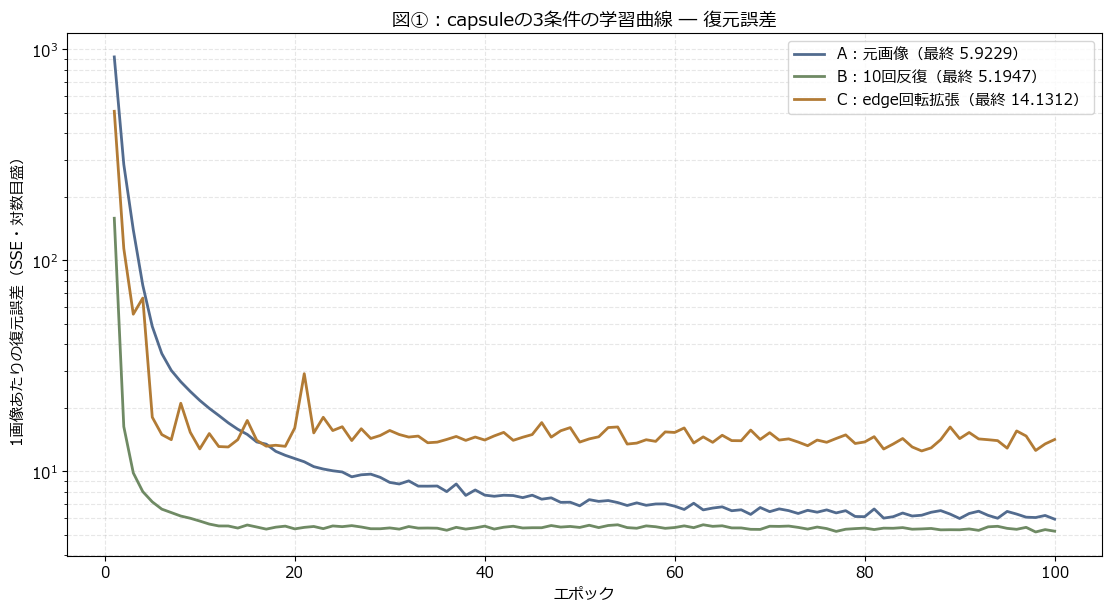

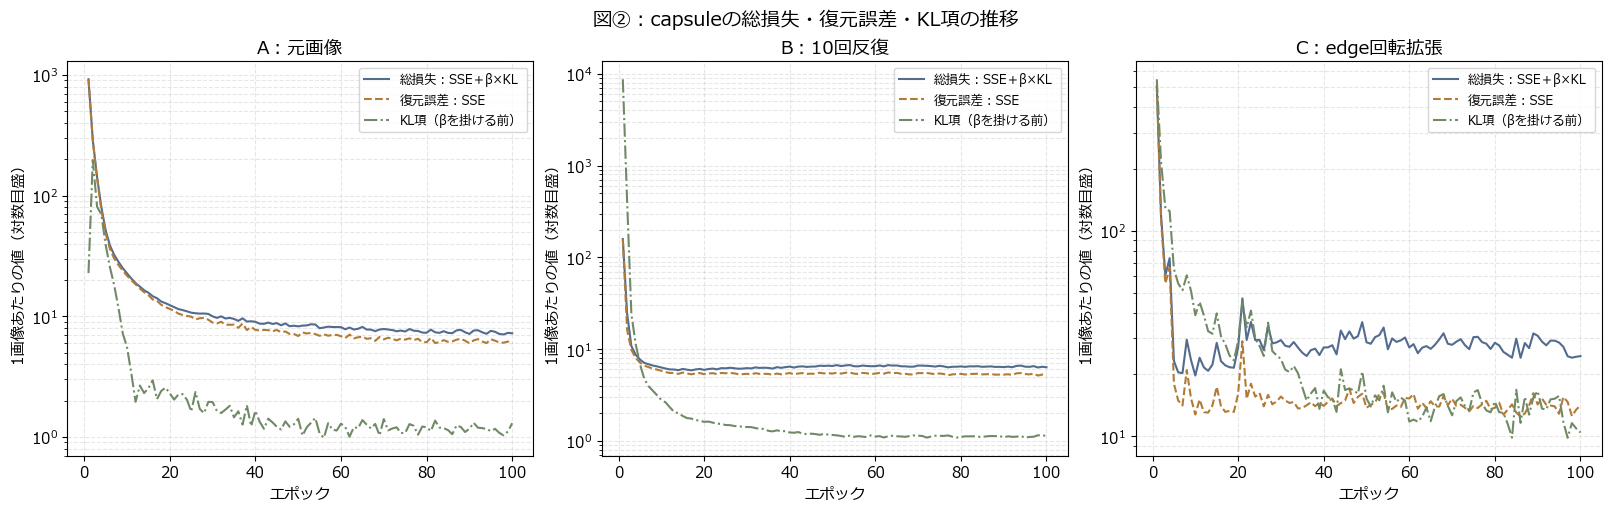

In [1]:
# このセル単独で、保存済みの学習ログからグラフを表示する（学習・推論は行わない）。
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

LEARNING_CURVE_RUN_ID = '20261023_002457_b5a8601a'
LEARNING_CURVE_SEED = 42
learning_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                      if (p / 'saved_models/capsule_rotation_control_20261022').is_dir()), None)
if learning_root is None:
    raise FileNotFoundError('このリポジトリ内を作業ディレクトリにしてください。')
learning_run_dir = (learning_root / 'saved_models/capsule_rotation_control_20261022'
                    / LEARNING_CURVE_RUN_ID / f'seed_{LEARNING_CURVE_SEED}')
learning_labels = {'A_original': 'A：元画像', 'B_repeat10': 'B：10回反復',
                   'C_rotate10': 'C：edge回転拡張'}
learning_colors = {'A_original': '#526b8e', 'B_repeat10': '#6f8a64', 'C_rotate10': '#b27b35'}
learning_histories = {}
for learning_condition in learning_labels:
    learning_path = learning_run_dir / learning_condition / 'history.csv'
    if not learning_path.is_file():
        raise FileNotFoundError(f'学習ログが見つかりません：{learning_path}')
    learning_frame = pd.read_csv(learning_path)
    learning_columns = ['epoch', 'beta', 'cumulative_updates', 'train_sse_per_image',
                        'train_kl_per_image', 'train_total_per_image']
    if not set(learning_columns).issubset(learning_frame.columns):
        raise ValueError(f'必要な列がありません：{learning_path}')
    if learning_frame.empty or not np.isfinite(learning_frame[learning_columns].to_numpy()).all():
        raise ValueError(f'空または非有限値を含むログです：{learning_path}')
    if not np.array_equal(learning_frame['epoch'].to_numpy(), np.arange(1, len(learning_frame) + 1)):
        raise ValueError(f'エポック番号が連続していません：{learning_path}')
    if not np.allclose(learning_frame.train_total_per_image,
                       learning_frame.train_sse_per_image + learning_frame.beta * learning_frame.train_kl_per_image):
        raise ValueError(f'総損失とSSE＋β×KLが一致しません：{learning_path}')
    learning_histories[learning_condition] = learning_frame

print(f'読み込み：{LEARNING_CURVE_RUN_ID} / seed={LEARNING_CURVE_SEED}（再学習なし）')
display(pd.DataFrame([{
    '条件': learning_labels[name], '記録エポック数': len(frame),
    '最終更新回数': int(frame.cumulative_updates.iloc[-1]),
    '最終学習SSE／画像': frame.train_sse_per_image.iloc[-1],
} for name, frame in learning_histories.items()]))

learning_font_names = {f.name for f in font_manager.fontManager.ttflist}
learning_font = next((name for name in ['Meiryo', 'Yu Gothic', 'MS Gothic',
                    'Noto Sans CJK JP', 'IPAexGothic'] if name in learning_font_names), None)
learning_style = {'font.size': 11, 'axes.unicode_minus': False, 'figure.dpi': 100}
if learning_font:
    learning_style['font.family'] = learning_font
with plt.rc_context(learning_style):
    fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
    for name, frame in learning_histories.items():
        ax.plot(frame.epoch, frame.train_sse_per_image, color=learning_colors[name],
                label=f'{learning_labels[name]}（最終 {frame.train_sse_per_image.iloc[-1]:.4f}）', linewidth=2)
    ax.set(xlabel='エポック', ylabel='1画像あたりの復元誤差（SSE・対数目盛）',
           yscale='log', title='図①：capsuleの3条件の学習曲線 ― 復元誤差')
    ax.legend(loc='upper right')
    ax.grid(True, which='both', linestyle='--', alpha=0.3)
    plt.show()
    plt.close(fig)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
    for ax, (name, frame) in zip(axes, learning_histories.items()):
        ax.plot(frame.epoch, frame.train_total_per_image, color='#526b8e', label='総損失：SSE＋β×KL')
        ax.plot(frame.epoch, frame.train_sse_per_image, color='#b27b35', linestyle='--', label='復元誤差：SSE')
        ax.plot(frame.epoch, frame.train_kl_per_image, color='#6f8a64', linestyle='-.', label='KL項（βを掛ける前）')
        ax.set(xlabel='エポック', ylabel='1画像あたりの値（対数目盛）', yscale='log', title=learning_labels[name])
        ax.legend(fontsize=9)
        ax.grid(True, which='both', linestyle='--', alpha=0.3)
    fig.suptitle('図②：capsuleの総損失・復元誤差・KL項の推移', fontsize=14)
    plt.show()
    plt.close(fig)
